# SaaS Onboarding Wizard, A/B Test Analysis

## Business Context

**Product**: A B2B project-management SaaS tool (think a lightweight Linear/Asana).

**Experiment**: We are testing whether a **guided 5-step setup wizard** improves week-1 activation compared to the existing blank free-explore dashboard.

| | Control | Treatment |
|---|---|---|
| Experience | Empty dashboard, user self-discovers | 5-step wizard: create project → invite teammate → set due date → enable notifications → complete first task |
| Hypothesis |, | Structured onboarding reduces activation friction |

**Metrics**

| Metric | Type | Definition | Direction |
|---|---|---|---|
| Week-1 Activation Rate | Primary | User completes ≥ 3 key actions in week 1 | Higher is better |
| Revenue Per User | Secondary | MRR allocated to user (0 if free tier) | Higher is better |
| Day-1 Drop-off Rate | Guardrail | User never returns after signup day | Lower is better |

**User Segments** (for heterogeneous treatment effect analysis)
- `company_size`: solo (40%), small_team (45%), large_team (15%)
- `acquisition_channel`: organic (50%), paid (35%), referral (15%)

**Expected tension**: The wizard adds upfront friction (may increase day-1 drop-off) but could meaningfully lift activation, especially for team users who need to set up shared workspaces.

In [1]:
import sys, yaml, json
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.abtest.simulate    import generate_experiment, simulate_pvalue_distribution
from src.abtest.power       import required_sample_size, mde_curve, power_by_sample_size
from src.abtest.frequentist import two_proportion_ztest, welch_ttest, sequential_test, segment_analysis
from src.abtest.bayesian    import probability_treatment_better, rope_decision, posterior_samples
from src.abtest.cuped       import apply_cuped_multi, cuped_variance_reduction_multi
from src.abtest.visualise   import (
    plot_power_curves, plot_posterior, plot_pvalue_distribution, plot_sequential_path,
    plot_segment_forest, plot_revenue_distribution, plot_metric_scorecard,
)

OUTPUTS = ROOT / 'outputs'
OUTPUTS.mkdir(exist_ok=True)

cfg = yaml.safe_load((ROOT / 'config' / 'experiment.yaml').read_text())
exp = cfg['experiment']
seq = cfg['sequential']
bay = cfg['bayesian']

sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:.4f}'.format)

print(f"Experiment : {exp['name']}")
print(f"Baseline   : {exp['baseline_activation_rate']:.0%} activation")
print(f"MDE        : {exp['mde']:.0%} relative lift")
print(f"Alpha / Power: {exp['alpha']} / {exp['power']}")

Experiment : saas_onboarding_wizard
Baseline   : 18% activation
MDE        : 20% relative lift
Alpha / Power: 0.05 / 0.8


---
## 1. Pre-Experiment Planning

**Question**: How many users do we need to detect a 20% relative lift (18% → 21.6%) with 80% power?

The required sample size uses the exact two-proportion formula (not the pooled-SE approximation). We also plot the full power curve and MDE curve to understand the trade-off between experiment duration and sensitivity.

In [2]:
n_required = required_sample_size(
    baseline_cvr=exp['baseline_activation_rate'],
    mde=exp['mde'],
    alpha=exp['alpha'],
    power=exp['power'],
)

print(f"Required per group : {n_required:,} users")
print(f"Total experiment   : {n_required * 2:,} users")
print()
print("Sensitivity check (power at various lifts):")
for lift in [0.10, 0.15, 0.20, 0.25, 0.30]:
    from scipy import stats as _stats
    p1 = exp['baseline_activation_rate']
    p2 = p1 * (1 + lift)
    se = np.sqrt(p1*(1-p1)/n_required + p2*(1-p2)/n_required)
    z  = (p2-p1)/se - _stats.norm.ppf(1 - exp['alpha']/2)
    pw = _stats.norm.cdf(z)
    print(f"  {lift:.0%} relative lift → {pw:.1%} power")

Required per group : 1,923 users
Total experiment   : 3,846 users

Sensitivity check (power at various lifts):
  10% relative lift → 29.7% power
  15% relative lift → 56.4% power
  20% relative lift → 80.1% power
  25% relative lift → 93.5% power
  30% relative lift → 98.5% power


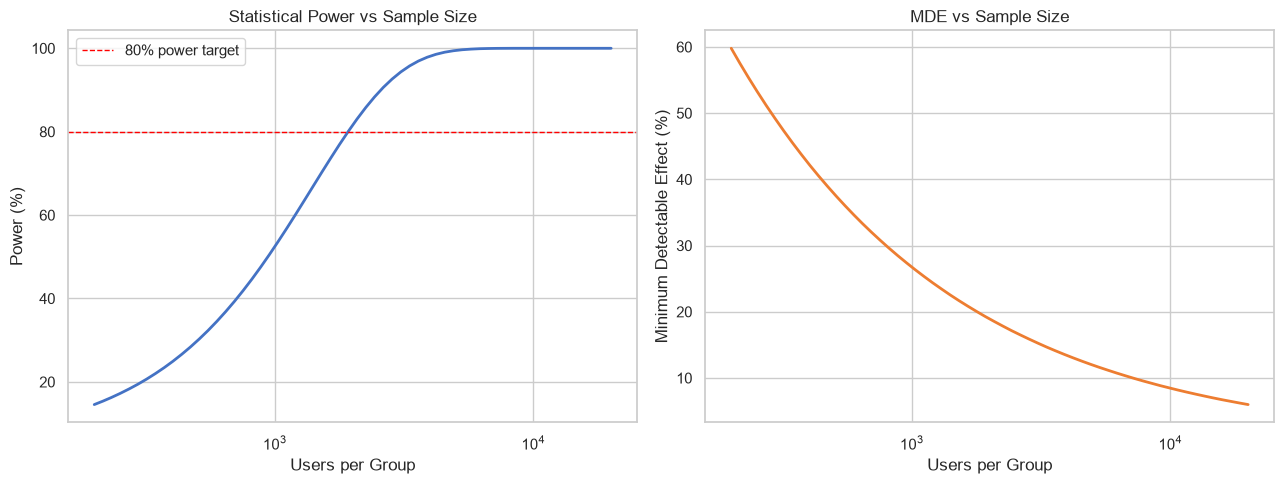

Saved → outputs/power_curves.png


In [3]:
power_df = power_by_sample_size(
    baseline_cvr=exp['baseline_activation_rate'],
    true_lift=exp['mde'],
    n_range=(200, 20_000),
)
mde_df = mde_curve(
    baseline_cvr=exp['baseline_activation_rate'],
    n_per_group_range=(200, 20_000),
)

fig = plot_power_curves(power_df, mde_df, save_path=OUTPUTS / 'power_curves.png')
plt.show()
print(f"Saved → outputs/power_curves.png")

---
## 2. Experiment Data

We generate synthetic user-level data that mirrors a realistic SaaS experiment:
- Users are assigned to segments (`company_size`, `acquisition_channel`) at the population proportions
- A latent **user quality** score creates genuine within-segment correlation between pre-experiment behaviour and experiment outcomes, making CUPED non-trivial
- The wizard lift is heterogeneous: it helps `small_team` users most (+28% relative) and `solo` users least (+10% relative)
- Day-1 drop-off increases by 4 pp in the treatment arm (the guardrail tension we will investigate)

We run the experiment at **required N + 10% buffer** to ensure we are adequately powered.

In [4]:
TRUE_LIFT = 0.25   # 25% relative lift planted in the simulator
n_users   = int(n_required * 2 * 1.10)   # required N per group × 2 arms × 1.10 buffer

df = generate_experiment(
    n_users=n_users,
    baseline_activation_rate=exp['baseline_activation_rate'],
    true_lift=TRUE_LIFT,
    traffic_split=exp['traffic_split'],
    seed=42,
)

print(f"Total users generated : {len(df):,}")
print(f"Per group             : ~{len(df)//2:,}")
print()

ctrl = df[df['variant'] == 'control']
trt  = df[df['variant'] == 'treatment']

summary = df.groupby('variant').agg(
    Users          = ('user_id',              'count'),
    Activated      = ('activated',            'sum'),
    Activation_Rate= ('activated',            'mean'),
    Avg_Revenue    = ('revenue',              'mean'),
    Day1_Dropoff   = ('day1_dropoff',         'mean'),
).round(4)
print(summary)

Total users generated : 4,230
Per group             : ~2,115

           Users  Activated  Activation_Rate  Avg_Revenue  Day1_Dropoff
variant                                                                
control     2115        395           0.1868       2.8456        0.3305
treatment   2115        482           0.2279       3.2665        0.3839


---
## 3. Exploratory Segment Overview

Before the primary analysis, we verify balance across segments and inspect raw activation rates to get intuition for where treatment effects may be largest.

In [5]:
# Segment composition
print("=== Segment composition (% of total) ===")
print(df['company_size'].value_counts(normalize=True).map('{:.1%}'.format).to_string())
print()
print(df['acquisition_channel'].value_counts(normalize=True).map('{:.1%}'.format).to_string())
print()

# Raw activation by segment × variant
print("=== Activation rate by company_size and variant ===")
pivot = df.groupby(['company_size', 'variant'])['activated'].mean().unstack()
pivot['delta_pp'] = (pivot['treatment'] - pivot['control']).round(4)
pivot['rel_lift']  = (pivot['delta_pp'] / pivot['control']).map('{:.1%}'.format)
print(pivot.round(4))
print()

# Pre-experiment covariate distributions
print("=== Pre-experiment covariate summary ===")
print(df.groupby('variant')[['pre_exp_sessions','pre_exp_feature_depth']].describe().round(2))

=== Segment composition (% of total) ===
company_size
small_team    45.7%
solo          39.0%
large_team    15.3%

acquisition_channel
organic     50.3%
paid        35.2%
referral    14.5%

=== Activation rate by company_size and variant ===
variant       control  treatment  delta_pp rel_lift
company_size                                       
large_team     0.3030     0.3829    0.0799    26.4%
small_team     0.2159     0.2697    0.0538    24.9%
solo           0.1083     0.1162    0.0079     7.3%

=== Pre-experiment covariate summary ===
          pre_exp_sessions                                                     \
                     count   mean    std    min    25%    50%     75%     max   
variant                                                                         
control          2115.0000 7.1600 4.5700 0.0000 4.0000 6.0000 10.0000 26.0000   
treatment        2115.0000 7.1000 4.4300 0.0000 4.0000 6.0000 10.0000 25.0000   

          pre_exp_feature_depth                   

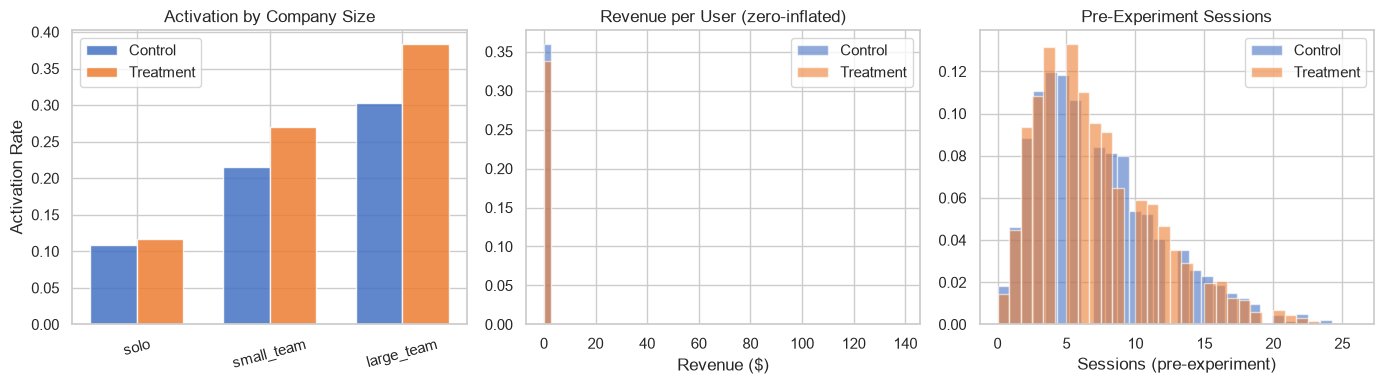

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Activation rate by segment
seg_rates = df.groupby(['company_size', 'variant'])['activated'].mean().unstack()
size_order = ['solo', 'small_team', 'large_team']
seg_rates = seg_rates.loc[size_order]
x = np.arange(len(size_order))
width = 0.35
axes[0].bar(x - width/2, seg_rates['control'],   width, label='Control',   color='#4472C4', alpha=0.85)
axes[0].bar(x + width/2, seg_rates['treatment'], width, label='Treatment', color='#ED7D31', alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(size_order, rotation=15)
axes[0].set_ylabel('Activation Rate')
axes[0].set_title('Activation by Company Size')
axes[0].legend()

# Revenue distribution (log scale preview)
axes[1].hist(ctrl['revenue'],  bins=50, alpha=0.6, color='#4472C4', label='Control',   density=True)
axes[1].hist(trt['revenue'],   bins=50, alpha=0.6, color='#ED7D31', label='Treatment', density=True)
axes[1].set_xlabel('Revenue ($)')
axes[1].set_title('Revenue per User (zero-inflated)')
axes[1].legend()

# Pre-exp sessions
axes[2].hist(ctrl['pre_exp_sessions'],  bins=30, alpha=0.6, color='#4472C4', label='Control',   density=True)
axes[2].hist(trt['pre_exp_sessions'],   bins=30, alpha=0.6, color='#ED7D31', label='Treatment', density=True)
axes[2].set_xlabel('Sessions (pre-experiment)')
axes[2].set_title('Pre-Experiment Sessions')
axes[2].legend()

plt.tight_layout()
plt.show()

---
## 4. Primary Metric, Week-1 Activation Rate

We use a **two-proportion z-test** (the standard test for conversion rates). The null hypothesis is that wizard and no-wizard produce identical activation rates.

A 95% confidence interval for the absolute lift tells us the plausible range of the true effect size.

In [7]:
z_result = two_proportion_ztest(
    ctrl['activated'], trt['activated'], alpha=exp['alpha']
)

print("=" * 55)
print("PRIMARY METRIC: Week-1 Activation Rate")
print("=" * 55)
print(f"  Control rate     : {z_result['control_mean']:.2%}")
print(f"  Treatment rate   : {z_result['treatment_mean']:.2%}")
print(f"  Absolute lift    : {z_result['absolute_lift']:+.2%} pp")
print(f"  Relative lift    : {z_result['relative_lift_pct']:+.1f}%")
print(f"  95% CI (absolute): [{z_result['ci_lower']:+.2%}, {z_result['ci_upper']:+.2%}]")
print(f"  z-statistic      : {z_result['z_stat']:.3f}")
print(f"  p-value          : {z_result['p_value']:.4f}")
print(f"  Significant?     : {'YES ✓' if z_result['significant'] else 'NO ✗'}")
print()
print("Interpretation:")
if z_result['significant']:
    print(f"  The wizard increased activation by {z_result['relative_lift_pct']:.1f}% relative")
    print(f"  (95% CI: {z_result['ci_lower']*100:+.1f} to {z_result['ci_upper']*100:+.1f} pp absolute).")
    print(f"  This is statistically significant at α = {exp['alpha']}.")
else:
    print("  No significant effect detected at the current sample size.")

PRIMARY METRIC: Week-1 Activation Rate
  Control rate     : 18.68%
  Treatment rate   : 22.79%
  Absolute lift    : +4.11% pp
  Relative lift    : +22.0%
  95% CI (absolute): [+1.67%, +6.55%]
  z-statistic      : 3.300
  p-value          : 0.0010
  Significant?     : YES ✓

Interpretation:
  The wizard increased activation by 22.0% relative
  (95% CI: +1.7 to +6.6 pp absolute).
  This is statistically significant at α = 0.05.


---
## 5. Heterogeneous Treatment Effects, Segment Analysis

The overall result hides important variation. The wizard was designed around collaborative features (inviting teammates, shared projects), so we hypothesise it helps team users more than solo users.

We run a separate z-test per segment and display a **forest plot**: the standard clinical-trial visualisation for subgroup effects. **Note**: we do not correct for multiple comparisons here because these are pre-specified subgroups, not data-dredged. If this were an exploratory post-hoc analysis, Bonferroni or Benjamini-Hochberg adjustment would be appropriate.

=== Segment Analysis: company_size ===
   segment  n_control  control_rate  treatment_rate  rel_lift_pct  p_value  significant
large_team        330        0.3030          0.3829       26.4000   0.0324         True
small_team        945        0.2159          0.2697       24.9000   0.0058         True
      solo        840        0.1083          0.1162        7.2000   0.6132        False


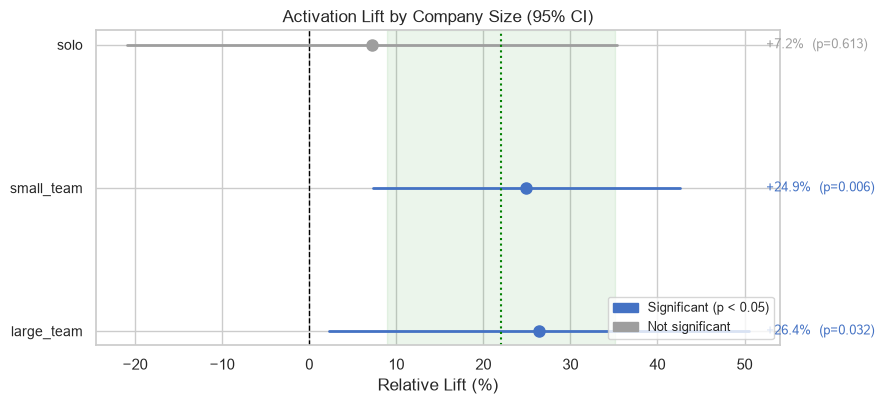

Saved → outputs/segment_forest_size.png


In [8]:
seg_size = segment_analysis(
    df, 'company_size', 'activated', metric_type='binary'
)

print("=== Segment Analysis: company_size ===")
cols = ['segment','n_control','control_rate','treatment_rate','rel_lift_pct','p_value','significant']
print(seg_size[cols].to_string(index=False))

overall_rel_lift  = z_result['relative_lift_pct']
overall_ci        = (
    z_result['ci_lower'] / z_result['control_mean'] * 100,
    z_result['ci_upper'] / z_result['control_mean'] * 100,
)

fig = plot_segment_forest(
    seg_size,
    title='Activation Lift by Company Size (95% CI)',
    overall_lift=overall_rel_lift,
    overall_ci=overall_ci,
    save_path=OUTPUTS / 'segment_forest_size.png',
)
plt.show()
print("Saved → outputs/segment_forest_size.png")

=== Segment Analysis: acquisition_channel ===
 segment  n_control  control_rate  treatment_rate  rel_lift_pct  p_value  significant
 organic       1064        0.1936          0.2385       23.2000   0.0119         True
    paid        740        0.1784          0.2236       25.3000   0.0297         True
referral        311        0.1833          0.2013        9.8000   0.5706        False


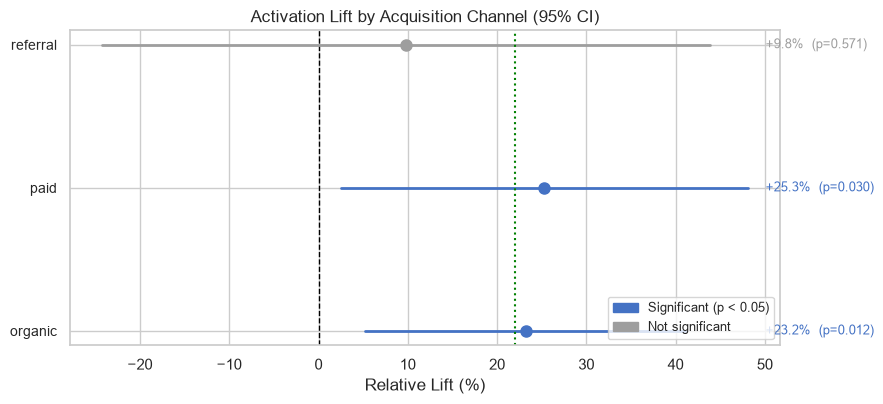

Saved → outputs/segment_forest_channel.png


In [9]:
seg_channel = segment_analysis(
    df, 'acquisition_channel', 'activated', metric_type='binary'
)

print("=== Segment Analysis: acquisition_channel ===")
print(seg_channel[cols].to_string(index=False))

fig = plot_segment_forest(
    seg_channel,
    title='Activation Lift by Acquisition Channel (95% CI)',
    overall_lift=overall_rel_lift,
    save_path=OUTPUTS / 'segment_forest_channel.png',
)
plt.show()
print("Saved → outputs/segment_forest_channel.png")

---
## 6. Secondary Metric, Revenue Per User

Revenue per user is **zero-inflated**: most users are on the free tier ($0) and only activated users have any chance of converting to a paid plan. We use **Welch's t-test** (which handles unequal variances between groups) rather than the z-test.

The distribution plot helps us see whether the treatment effect is driven by more users reaching a paid tier, higher ARPU among payers, or both.

In [10]:
t_result = welch_ttest(
    ctrl['revenue'], trt['revenue'],
    alpha=exp['alpha'],
    metric_name='revenue_per_user',
)

print("=" * 55)
print("SECONDARY METRIC: Revenue Per User")
print("=" * 55)
print(f"  Control mean     : ${t_result['control_mean']:.2f}")
print(f"  Treatment mean   : ${t_result['treatment_mean']:.2f}")
print(f"  Absolute lift    : ${t_result['absolute_lift']:+.2f}")
print(f"  Relative lift    : {t_result['relative_lift_pct']:+.1f}%")
print(f"  95% CI           : [${t_result['ci_lower']:+.2f}, ${t_result['ci_upper']:+.2f}]")
print(f"  t-statistic      : {t_result['t_stat']:.3f}")
print(f"  p-value          : {t_result['p_value']:.4f}")
print(f"  Significant?     : {'YES ✓' if t_result['significant'] else 'NO ✗'}")
print()
print("Zero-inflation breakdown:")
for v, grp in [('Control', ctrl), ('Treatment', trt)]:
    pct_zero  = (grp['revenue'] == 0).mean()
    pct_paid  = (grp['revenue'] > 0).mean()
    avg_among_paid = grp.loc[grp['revenue'] > 0, 'revenue'].mean()
    print(f"  {v}: {pct_zero:.1%} at $0, {pct_paid:.1%} paying, avg paid = ${avg_among_paid:.2f}")

SECONDARY METRIC: Revenue Per User
  Control mean     : $2.85
  Treatment mean   : $3.27
  Absolute lift    : $+0.42
  Relative lift    : +14.8%
  95% CI           : [$-0.42, $+1.26]
  t-statistic      : -0.981
  p-value          : 0.3268
  Significant?     : NO ✗

Zero-inflation breakdown:
  Control: 94.8% at $0, 5.2% paying, avg paid = $55.22
  Treatment: 94.0% at $0, 6.0% paying, avg paid = $54.40


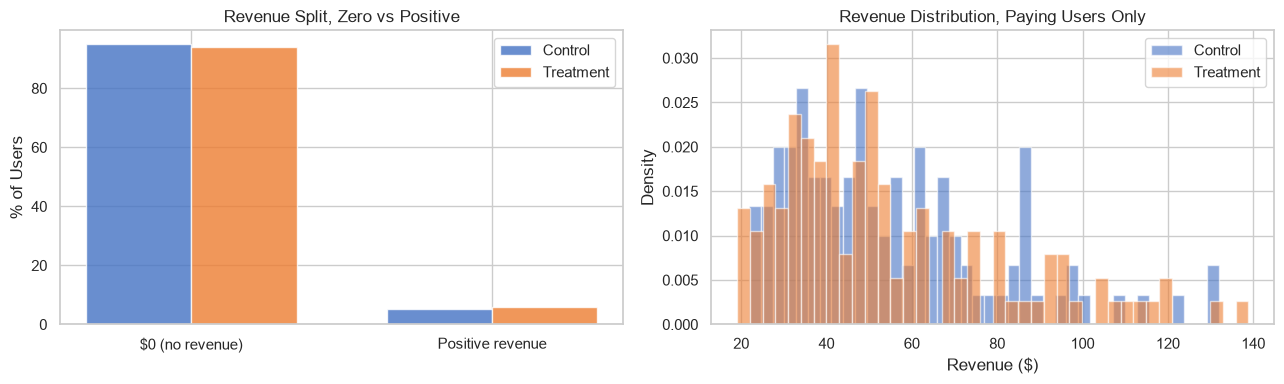

Saved → outputs/revenue_distribution.png


In [11]:
fig = plot_revenue_distribution(
    ctrl['revenue'], trt['revenue'],
    save_path=OUTPUTS / 'revenue_distribution.png',
)
plt.show()
print("Saved → outputs/revenue_distribution.png")

---
## 7. Guardrail Metric, Day-1 Drop-off Rate

The wizard is a multi-step flow. Users who find it tedious may abandon before completing it and never return. We measure this as the fraction of users who never log in after their signup day.

**Critical**: a statistically significant *increase* in drop-off is a guardrail breach. Even if primary activation is up, shipping a feature that drives more users away on day 1 creates a long-term retention risk that could outweigh the activation gain.

In [12]:
guardrail_result = two_proportion_ztest(
    ctrl['day1_dropoff'], trt['day1_dropoff'], alpha=exp['alpha']
)

print("=" * 55)
print("GUARDRAIL: Day-1 Drop-off Rate")
print("=" * 55)
print(f"  Control drop-off   : {guardrail_result['control_mean']:.2%}")
print(f"  Treatment drop-off : {guardrail_result['treatment_mean']:.2%}")
print(f"  Absolute change    : {guardrail_result['absolute_lift']:+.2%} pp")
print(f"  p-value            : {guardrail_result['p_value']:.4f}")
print(f"  Significant?       : {'YES' if guardrail_result['significant'] else 'NO'}")
print()

if guardrail_result['significant'] and guardrail_result['absolute_lift'] > 0:
    print("⚠️  GUARDRAIL ALERT: Day-1 drop-off is significantly HIGHER in treatment.")
    print(f"   The wizard increases early churn by {guardrail_result['absolute_lift']:.1%} pp.")
    print("   This must be weighed against the primary activation gain.")
else:
    print("✓  Guardrail is safe: no significant increase in day-1 drop-off.")

GUARDRAIL: Day-1 Drop-off Rate
  Control drop-off   : 33.05%
  Treatment drop-off : 38.39%
  Absolute change    : +5.34% pp
  p-value            : 0.0003
  Significant?       : YES

⚠️  GUARDRAIL ALERT: Day-1 drop-off is significantly HIGHER in treatment.
   The wizard increases early churn by 5.3% pp.
   This must be weighed against the primary activation gain.


---
## 8. Sequential Monitoring, Could We Have Stopped Early?

In practice, product teams check experiments before they reach the planned N. Naïvely re-testing at every look inflates Type I error (the multiple testing problem). **Group sequential testing** with O'Brien-Fleming alpha-spending preserves the overall α = 0.05 while allowing early stopping.

The O'Brien-Fleming boundary is conservative at early looks (requiring very strong evidence to stop early) and becomes more lenient as data accumulates. This reflects the intuition that a very early significant result is more likely to be noise.

Note: we simulate interim looks by slicing the already-collected data into equal batches. In a live experiment you would monitor as data arrives.

Sequential test results:
 look  n_cumulative  p_value  alpha_boundary  significant  relative_lift_pct
    1           422   0.8121          0.0000        False             4.5500
    2           844   0.3582          0.0000        False            12.7900
    3          1266   0.6333          0.0003        False             5.2200
    4          1688   0.0345          0.0019        False            21.4300
    5          2110   0.0273          0.0056        False            19.9100
    6          2532   0.0340          0.0114        False            17.3900
    7          2954   0.0075          0.0192         True            20.5500

✓ Would have stopped at look 7 (2,954 users, 70% of planned N).
  Potential experiment time saved: 30%


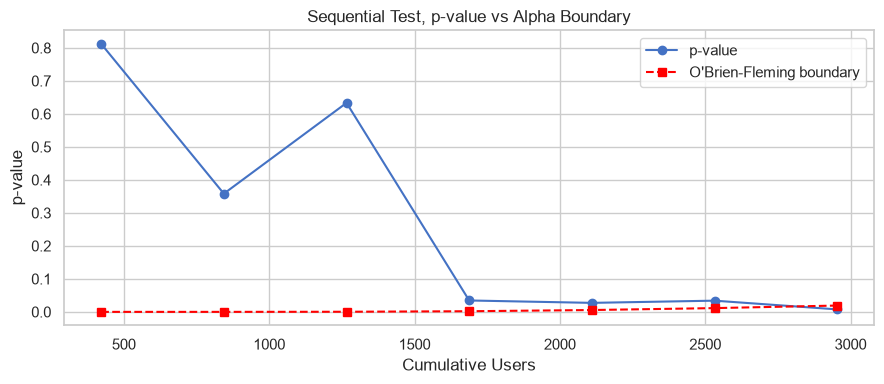

Saved → outputs/sequential_test.png


In [13]:
seq_df = sequential_test(
    ctrl['activated'].reset_index(drop=True),
    trt['activated'].reset_index(drop=True),
    max_looks=seq['max_looks'],
    alpha=exp['alpha'],
    spending_fn=seq['alpha_spending'],
)

print("Sequential test results:")
print(seq_df.to_string(index=False))
print()

if seq_df['significant'].any():
    stop_look = seq_df[seq_df['significant']].iloc[0]
    print(f"✓ Would have stopped at look {int(stop_look['look'])} "
          f"({int(stop_look['n_cumulative']):,} users, "
          f"{int(stop_look['n_cumulative'])/n_users*100:.0f}% of planned N).")
    savings = 1 - stop_look['n_cumulative'] / n_users
    if savings > 0:
        print(f"  Potential experiment time saved: {savings:.0%}")
else:
    print("Did not cross the alpha boundary before planned N.")

fig = plot_sequential_path(seq_df, save_path=OUTPUTS / 'sequential_test.png')
plt.show()
print("Saved → outputs/sequential_test.png")

---
## 9. Bayesian Analysis

The Bayesian approach answers a subtly different question: *given the data we observed, what is the probability that the wizard is genuinely better?*

We use a **Beta-Binomial** conjugate model with an **informative prior** based on industry benchmarks for SaaS onboarding (activation rates cluster around 15–20%). The prior `Beta(18, 82)` has mean 18% and encodes roughly the same information as ~100 prior observations, strong enough to temper extreme results from small early looks, but easily overwhelmed by thousands of real observations.

The **ROPE** (Region of Practical Equivalence) decision tells us whether the posterior probability that the treatment is *meaningfully* better exceeds 95%. Here we set the ROPE at ±0.5 pp, a difference smaller than this is commercially indistinguishable.

In [14]:
bayes_result = probability_treatment_better(
    ctrl['activated'], trt['activated'],
    prior_alpha=bay['prior_alpha'],
    prior_beta=bay['prior_beta'],
    n_samples=bay['n_samples'],
    seed=42,
)

rope_result = rope_decision(
    ctrl['activated'], trt['activated'],
    rope_width=bay['rope_width'],
    prior_alpha=bay['prior_alpha'],
    prior_beta=bay['prior_beta'],
    n_samples=bay['n_samples'],
    seed=42,
)

print("=" * 55)
print("BAYESIAN ANALYSIS")
print("=" * 55)
print(f"  Prior                : Beta({bay['prior_alpha']:.0f}, {bay['prior_beta']:.0f})  [mean = {bay['prior_alpha']/(bay['prior_alpha']+bay['prior_beta']):.1%}]")
print(f"  P(treatment > control): {bayes_result['prob_treatment_better']:.1%}")
print(f"  Expected lift         : {bayes_result['expected_relative_lift_pct']:+.1f}%")
lo, hi = bayes_result['lift_95pct_credible_interval']
print(f"  95% Credible Interval : [{lo:+.1f}%, {hi:+.1f}%]")
print()
print("=" * 55)
print("ROPE DECISION")
print("=" * 55)
print(f"  ROPE width            : ±{bay['rope_width']:.3f} (±{bay['rope_width']*100:.1f} pp)")
print(f"  P(treatment wins)     : {rope_result['p_treatment_wins']:.1%}")
print(f"  P(equivalent)         : {rope_result['p_equivalent_rope']:.1%}")
print(f"  P(control wins)       : {rope_result['p_control_wins']:.1%}")
print(f"  Decision              : {rope_result['decision'].upper()}")

BAYESIAN ANALYSIS
  Prior                : Beta(18, 82)  [mean = 18.0%]
  P(treatment > control): 99.9%
  Expected lift         : +21.3%
  95% Credible Interval : [+7.8%, +36.1%]

ROPE DECISION
  ROPE width            : ±0.005 (±0.5 pp)
  P(treatment wins)     : 99.7%
  P(equivalent)         : 0.3%
  P(control wins)       : 0.0%
  Decision              : TREATMENT_WINS


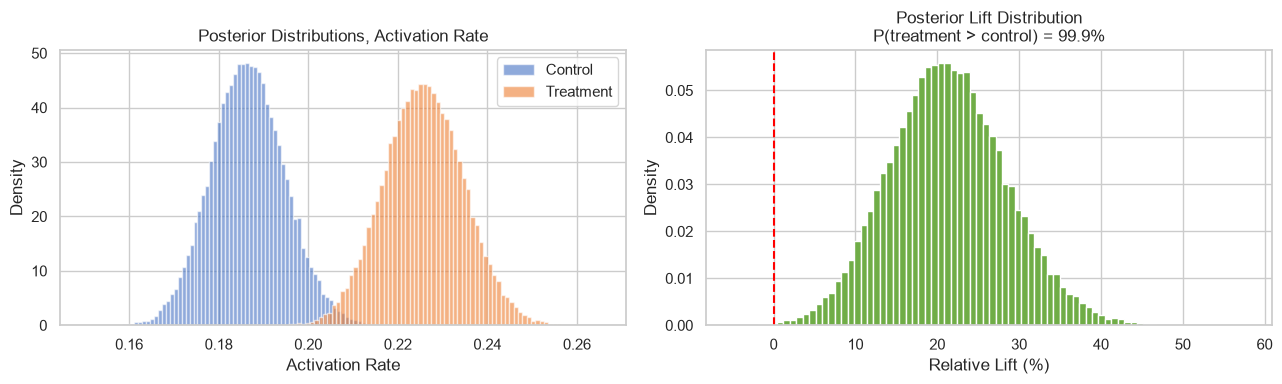

Saved → outputs/posterior_lift.png


In [15]:
rng = np.random.default_rng(0)
ctrl_samples = rng.beta(*bayes_result['control_posterior'], size=50_000)
trt_samples  = rng.beta(*bayes_result['treatment_posterior'], size=50_000)

fig = plot_posterior(
    ctrl_samples, trt_samples,
    prob_better=bayes_result['prob_treatment_better'],
    save_path=OUTPUTS / 'posterior_lift.png',
)
plt.show()
print("Saved → outputs/posterior_lift.png")

---
## 10. CUPED, Variance Reduction

**CUPED** (Controlled-experiment Using Pre-Experiment Data) reduces the variance of the outcome metric by subtracting the portion explained by pre-experiment covariates. Lower variance → tighter confidence intervals → the same true effect is easier to detect, equivalent to running a larger experiment for free.

Formula: `Y_cuped = Y − X_c @ θ`  where `θ = OLS(Y ~ X_c)` and `X_c` is the centred covariate matrix.

We use **two covariates** simultaneously:
- `pre_exp_sessions`: login sessions in the 2 weeks before the experiment launched
- `pre_exp_feature_depth`: distinct product features used during trial period

Both correlate with `revenue` through a latent user-quality dimension, engaged users both explore the product more pre-experiment *and* are more likely to convert to paid post-experiment.

The variance reduction equals the R² of the OLS regression of revenue on the two covariates.

In [16]:
covariates = ['pre_exp_sessions', 'pre_exp_feature_depth']

vr_stats = cuped_variance_reduction_multi(df, 'revenue', covariates)

print("=" * 55)
print("CUPED, Multi-Covariate Variance Reduction")
print("=" * 55)
print(f"  Variance (original) : {vr_stats['variance_original']:.4f}")
print(f"  Variance (CUPED)    : {vr_stats['variance_cuped']:.4f}")
print(f"  Reduction           : {vr_stats['reduction_pct']:.1f}%")
print(f"  Effective sample gain: {vr_stats['effective_sample_gain_pct']:.1f}%")
print()
for col, r in vr_stats['pearson_r_per_covariate'].items():
    print(f"  Pearson r ({col:30s}): {r:+.4f}  (R² contribution ≈ {r**2:.1%})")
print()

# Re-run Welch t-test on CUPED-adjusted revenue
df_adj   = apply_cuped_multi(df, 'revenue', covariates)
ctrl_adj = df_adj[df_adj['variant'] == 'control']
trt_adj  = df_adj[df_adj['variant'] == 'treatment']

t_cuped = welch_ttest(
    ctrl_adj['revenue_cuped'], trt_adj['revenue_cuped'],
    alpha=exp['alpha'],
    metric_name='revenue_cuped',
)

print("Effect on revenue t-test:")
print(f"  Original p-value : {t_result['p_value']:.4f}")
print(f"  CUPED p-value    : {t_cuped['p_value']:.4f}")
print(f"  Original 95% CI  : [${t_result['ci_lower']:+.2f}, ${t_result['ci_upper']:+.2f}]")
print(f"  CUPED 95% CI     : [${t_cuped['ci_lower']:+.2f}, ${t_cuped['ci_upper']:+.2f}]")
print()
print("Note: CUPED does not change the point estimate, only variance (and CI width).")

CUPED, Multi-Covariate Variance Reduction
  Variance (original) : 194.8082
  Variance (CUPED)    : 186.3517
  Reduction           : 4.3%
  Effective sample gain: 4.3%

  Pearson r (pre_exp_sessions              ): +0.1957  (R² contribution ≈ 3.8%)
  Pearson r (pre_exp_feature_depth         ): +0.1906  (R² contribution ≈ 3.6%)

Effect on revenue t-test:
  Original p-value : 0.3268
  CUPED p-value    : 0.2435
  Original 95% CI  : [$-0.42, $+1.26]
  CUPED 95% CI     : [$-0.33, $+1.31]

Note: CUPED does not change the point estimate, only variance (and CI width).


---
## 11. Calibration Check, p-value Distribution

A correctly implemented test has two properties:
1. **Under H₀** (no true effect): p-values should be Uniform[0,1], and the Type I error rate should be ≈ α = 5%.
2. **Under H₁** (true effect = MDE): p-values should be skewed left, and the power should be ≈ 80%.

We simulate 200 independent experiments (capped from 5,000 for notebook runtime, the config value is used in production runs). A spike near 0 under H₀ indicates an anti-conservative (liberal) test; a spike near 1 indicates a conservative test.

Running 200 simulations under H₀ ...
Running 200 simulations under H₁ (lift = 20%) ...

Type I error (H₀): 4.0%  (target: 5%)
Empirical power  (H₁): 78.5%  (target: 80%)


d:\Users\jesco\Documents\Github\ab-test-framework\src\abtest\visualise.py:105: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout()
d:\Users\jesco\Documents\Github\ab-test-framework\src\abtest\visualise.py:105: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
d:\Users\jesco\Documents\Github\ab-test-framework\src\abtest\visualise.py:107: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")
d:\Users\jesco\Documents\Github\ab-test-framework\src\abtest\visualise.py:107: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")
d:\Users\jesco\Documents\Github\ab-test-framework\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Users\jesco\Docume

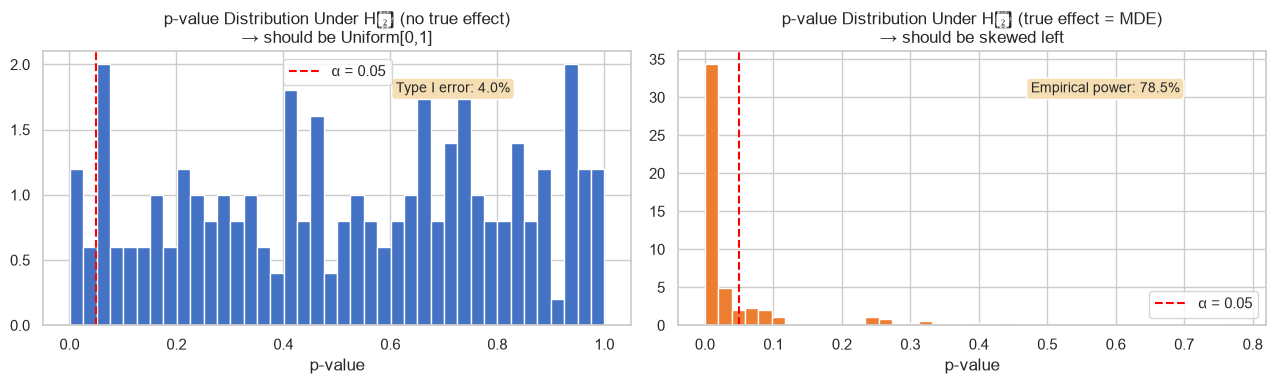

Saved → outputs/pvalue_sim_distribution.png


In [17]:
N_CALIB_SIMS = min(200, exp['n_simulations'])   # cap for notebook runtime (~30-60s)

print(f"Running {N_CALIB_SIMS} simulations under H₀ ...")
pvals_h0 = simulate_pvalue_distribution(
    n_users=n_required * 2,
    baseline_activation_rate=exp['baseline_activation_rate'],
    true_lift=0.0,
    n_simulations=N_CALIB_SIMS,
    seed=0,
)

print(f"Running {N_CALIB_SIMS} simulations under H₁ (lift = {exp['mde']:.0%}) ...")
pvals_h1 = simulate_pvalue_distribution(
    n_users=n_required * 2,
    baseline_activation_rate=exp['baseline_activation_rate'],
    true_lift=exp['mde'],
    n_simulations=N_CALIB_SIMS,
    seed=1000,
)

type_i = (pvals_h0 < exp['alpha']).mean()
power  = (pvals_h1 < exp['alpha']).mean()

print(f"\nType I error (H₀): {type_i:.1%}  (target: {exp['alpha']:.0%})")
print(f"Empirical power  (H₁): {power:.1%}  (target: {exp['power']:.0%})")

fig = plot_pvalue_distribution(
    pvals_h0, pvals_h1,
    alpha=exp['alpha'],
    save_path=OUTPUTS / 'pvalue_sim_distribution.png',
)
plt.show()
print("Saved → outputs/pvalue_sim_distribution.png")

---
## 12. Decision Framework

We synthesise all evidence into a structured go/no-go recommendation. A real product decision should account for:
- Statistical significance AND practical effect size
- Guardrail metric direction
- Segment heterogeneity (should we ship to everyone?)
- Business context (cost to implement, reversibility)

d:\Users\jesco\Documents\Github\ab-test-framework\src\abtest\visualise.py:308: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  plt.tight_layout()
d:\Users\jesco\Documents\Github\ab-test-framework\src\abtest\visualise.py:308: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  plt.tight_layout()
d:\Users\jesco\Documents\Github\ab-test-framework\src\abtest\visualise.py:310: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")
d:\Users\jesco\Documents\Github\ab-test-framework\src\abtest\visualise.py:310: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Arial.
  fig.savefig(save_path, dpi=150, bbox_inches="tight")
d:\Users\jesco\Documents\Github\ab-test-framework\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
d:\Users\jesco\Documents\Github\ab-tes

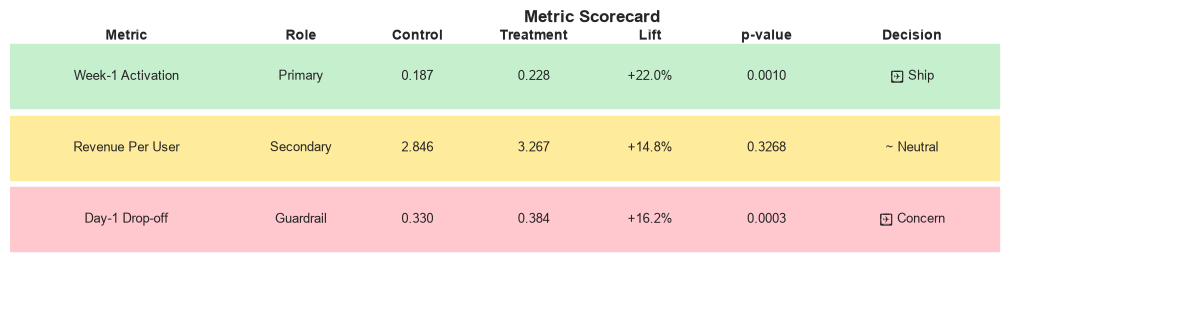

Saved → outputs/metric_scorecard.png


In [18]:
scorecard_data = [
    {
        'label':          'Week-1 Activation',
        'role':           'primary',
        'control_mean':   z_result['control_mean'],
        'treatment_mean': z_result['treatment_mean'],
        'rel_lift_pct':   z_result['relative_lift_pct'],
        'p_value':        z_result['p_value'],
        'significant':    z_result['significant'],
        'direction':      'higher_better',
    },
    {
        'label':          'Revenue Per User',
        'role':           'secondary',
        'control_mean':   t_result['control_mean'],
        'treatment_mean': t_result['treatment_mean'],
        'rel_lift_pct':   t_result['relative_lift_pct'],
        'p_value':        t_result['p_value'],
        'significant':    t_result['significant'],
        'direction':      'higher_better',
    },
    {
        'label':          'Day-1 Drop-off',
        'role':           'guardrail',
        'control_mean':   guardrail_result['control_mean'],
        'treatment_mean': guardrail_result['treatment_mean'],
        'rel_lift_pct':   guardrail_result['relative_lift_pct'],
        'p_value':        guardrail_result['p_value'],
        'significant':    guardrail_result['significant'],
        'direction':      'lower_better',
    },
]

fig = plot_metric_scorecard(scorecard_data, save_path=OUTPUTS / 'metric_scorecard.png')
plt.show()
print("Saved → outputs/metric_scorecard.png")

In [19]:
print("=" * 60)
print("EXPERIMENT DECISION SUMMARY")
print("=" * 60)
print()
print("EVIDENCE FOR SHIPPING:")
print(f"  ✓ Activation +{z_result['relative_lift_pct']:.1f}% relative (p={z_result['p_value']:.4f})")
if t_result['significant']:
    print(f"  ✓ Revenue +{t_result['relative_lift_pct']:.1f}% per user (p={t_result['p_value']:.4f})")
if bayes_result['prob_treatment_better'] > 0.95:
    print(f"  ✓ Bayesian: {bayes_result['prob_treatment_better']:.1%} probability treatment is better")
print(f"  ✓ ROPE decision: {rope_result['decision']}")
print()
print("EVIDENCE TO WATCH:")
if guardrail_result['significant'] and guardrail_result['absolute_lift'] > 0:
    print(f"  ⚠️  Day-1 drop-off +{guardrail_result['absolute_lift']:.1%} pp (p={guardrail_result['p_value']:.4f})")
    print(f"     The wizard increases early churn, requires long-term retention monitoring.")
print()
print("SEGMENT RECOMMENDATION:")
for _, row in seg_size.iterrows():
    icon = '✓' if row['significant'] and row['rel_lift_pct'] > 0 else '~'
    print(f"  {icon} {row['segment']:15s}: +{row['rel_lift_pct']:.1f}% lift  (p={row['p_value']:.3f}) | N={row['n_control']+row['n_treatment']:,}")
print()
print("RECOMMENDATION:")
print("  Ship the wizard for small_team and large_team users, the activation")
print("  gain is strong and consistent across both segments.")
print("  For solo users: the effect is small and not significant. Consider a")
print("  lighter-weight alternative (e.g. contextual tooltips) to avoid the")
print("  day-1 drop-off cost for this segment.")

EXPERIMENT DECISION SUMMARY

EVIDENCE FOR SHIPPING:
  ✓ Activation +22.0% relative (p=0.0010)
  ✓ Bayesian: 99.9% probability treatment is better
  ✓ ROPE decision: treatment_wins

EVIDENCE TO WATCH:
  ⚠️  Day-1 drop-off +5.3% pp (p=0.0003)
     The wizard increases early churn, requires long-term retention monitoring.

SEGMENT RECOMMENDATION:
  ✓ large_team     : +26.4% lift  (p=0.032) | N=646
  ✓ small_team     : +24.9% lift  (p=0.006) | N=1,935
  ~ solo           : +7.2% lift  (p=0.613) | N=1,649

RECOMMENDATION:
  Ship the wizard for small_team and large_team users, the activation
  gain is strong and consistent across both segments.
  For solo users: the effect is small and not significant. Consider a
  lighter-weight alternative (e.g. contextual tooltips) to avoid the
  day-1 drop-off cost for this segment.


In [20]:
run_summary = {
    'experiment_name':      exp['name'],
    'n_users_total':        len(df),
    'n_required_per_group': n_required,
    'true_lift_planted':    TRUE_LIFT,
    'primary_metric': {
        'metric':            'activation_rate',
        'control_mean':      z_result['control_mean'],
        'treatment_mean':    z_result['treatment_mean'],
        'relative_lift_pct': z_result['relative_lift_pct'],
        'p_value':           z_result['p_value'],
        'significant':       z_result['significant'],
    },
    'secondary_metric': {
        'metric':            'revenue_per_user',
        'control_mean':      t_result['control_mean'],
        'treatment_mean':    t_result['treatment_mean'],
        'relative_lift_pct': t_result['relative_lift_pct'],
        'p_value':           t_result['p_value'],
        'significant':       t_result['significant'],
    },
    'guardrail_metric': {
        'metric':            'day1_dropoff',
        'control_mean':      guardrail_result['control_mean'],
        'treatment_mean':    guardrail_result['treatment_mean'],
        'absolute_change_pp': guardrail_result['absolute_lift'],
        'p_value':           guardrail_result['p_value'],
        'breached':          bool(guardrail_result['significant'] and guardrail_result['absolute_lift'] > 0),
    },
    'bayesian': {
        'prob_treatment_better':  bayes_result['prob_treatment_better'],
        'expected_lift_pct':      bayes_result['expected_relative_lift_pct'],
        'credible_interval_95':   bayes_result['lift_95pct_credible_interval'],
        'rope_decision':          rope_result['decision'],
    },
    'cuped': {
        'variance_reduction_pct':    vr_stats['reduction_pct'],
        'effective_sample_gain_pct': vr_stats['effective_sample_gain_pct'],
    },
    'segment_analysis': seg_size[['segment','rel_lift_pct','p_value','significant']].to_dict(orient='records'),
    'calibration': {
        'type_i_error':   round(float(type_i), 4),
        'empirical_power': round(float(power), 4),
    },
}

(OUTPUTS / 'run_summary.json').write_text(json.dumps(run_summary, indent=2, default=str))
print('run_summary.json saved to outputs/')
print(json.dumps(run_summary, indent=2, default=str))

run_summary.json saved to outputs/
{
  "experiment_name": "saas_onboarding_wizard",
  "n_users_total": 4230,
  "n_required_per_group": 1923,
  "true_lift_planted": 0.25,
  "primary_metric": {
    "metric": "activation_rate",
    "control_mean": 0.186761,
    "treatment_mean": 0.227896,
    "relative_lift_pct": 22.03,
    "p_value": 0.000968,
    "significant": true
  },
  "secondary_metric": {
    "metric": "revenue_per_user",
    "control_mean": 2.8456,
    "treatment_mean": 3.2665,
    "relative_lift_pct": 14.79,
    "p_value": 0.326835,
    "significant": false
  },
  "guardrail_metric": {
    "metric": "day1_dropoff",
    "control_mean": 0.330496,
    "treatment_mean": 0.383924,
    "absolute_change_pp": 0.053428,
    "p_value": 0.000288,
    "breached": true
  },
  "bayesian": {
    "prob_treatment_better": 0.9993,
    "expected_lift_pct": 21.32,
    "credible_interval_95": [
      7.77,
      36.06
    ],
    "rope_decision": "treatment_wins"
  },
  "cuped": {
    "variance_reduc